<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/32_Attention_Mechanisms_%26_Transformers_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Attention Mechanism

Our Seq2Seq model can now translate a source sequence using an encoder and a decoder.

However, the basic model has an important limitation.

The encoder reads the entire source sequence and compresses its information into a **fixed-size representation** that is passed to the decoder.

By **compression**, we mean that information from many source tokens must be represented using a limited-size hidden representation.

For short sequences, this may work reasonably well. For longer sequences, however, important information may be difficult to preserve in this single representation.

## Intuition

Suppose the source sentence is:

`I love deep learning`

and the decoder is generating a French translation.

At decoder time step $t$, the decoder considers the encoder representations:

$$
h_1, h_2, \ldots, h_T
$$

and assigns an **attention weight** to each one:

$$
\alpha_{t,1}, \alpha_{t,2}, \ldots, \alpha_{t,T}
$$

where $\alpha_{t,i}$ represents how much attention the decoder gives to source position $i$ while generating the target token at time step $t$.

These attention weights satisfy:

$$
\sum_{i=1}^{T} \alpha_{t,i} = 1
$$

The decoder then combines the encoder representations using these weights to create a **context vector**:

$$
c_t = \sum_{i=1}^{T} \alpha_{t,i} h_i
$$

where:

- $c_t$ = context vector used at decoder time step $t$
- $\alpha_{t,i}$ = attention weight for source position $i$
- $h_i$ = encoder representation at source position $i$




Therefore, the context vector can be different at every decoder time step.

When generating one target word, the decoder may focus strongly on one part of the source sentence. When generating the next word, its attention can shift to another part.

The central question attention answers is:

> **Which parts of the source sequence are most useful for generating the current target token?**


## Basic Seq2Seq Vs Attention

In our basic Seq2Seq model:

`Source → Encoder → Fixed-Size Representation → Decoder`

With attention:

`Source → Encoder Outputs → Attention → Context Vector → Decoder`

Instead of depending only on one compressed representation of the source sequence, the decoder can now dynamically use information from the encoder outputs throughout the decoding process.

# Queries, Keys, and Values

We have seen that attention creates a context vector by taking a weighted combination of the encoder outputs:

$$
c_t = \sum_{i=1}^{T} \alpha_{t,i} h_i
$$

where:

- $c_t$ = context vector used at decoder time step $t$
- $\alpha_{t,i}$ = attention weight for source position $i$
- $h_i$ = encoder representation at source position $i$

But this raises an important question:

> **How does the model determine the attention weights $\alpha_{t,i}$?**

To answer this, attention introduces three ideas:

- **Query**
- **Key**
- **Value**




Think of attention as a **search**.

At decoder time step $t$, the decoder is asking:

> **Which source position contains information that is most useful to me right now?**

**The information used in this search** can be described using a **query**, **keys**, and **values**.


Suppose we are translating:

**English:** `They are watching the game.`  
**French:** `Ils regardent le match.`

At one decoder time step, the decoder may be trying to generate the French word:

**`regardent`**

At this moment, the decoder needs to determine which part of the English sentence is most useful.

It should pay more attention to: **`watching`** than to words such as `they`, `are`, or `game`.





The **information used in this search** can be described using three ideas:

- **Query** — what the decoder is currently looking for
- **Keys** — what each source position can be matched against
- **Values** — the information available at each source position

### Query

The **query** represents what the decoder is currently looking for.

We denote the query at decoder time step $t$ as:

$$
q_t
$$

Suppose we are translating:

**English:** `They are watching the game.`  
**French:** `Ils regardent le match.`

If the decoder has already generated `Ils`, its current hidden state contains information about what has been generated so far and what may be needed next.

This decoder information is used to form the **query** $q_t$.

The query will be compared with information from the source sentence to determine which source positions are most relevant.

**The query is** information derived from the decoder's current state that is used to determine which parts of the source sequence are most relevant for predicting the next token.

### Keys

Each source position has a **key**:

$$
k_1, k_2, \ldots, k_T
$$

The query is compared with these keys to determine how relevant each source position is.

Suppose we are translating:

**English:** `They are watching the game.`  
**French generated so far:** `Ils`

The decoder forms a query $q_t$ based on its current state.

The English source positions provide keys:

`They` → $k_1$  
`are` → $k_2$  
`watching` → $k_3$  
`the` → $k_4$  
`game` → $k_5$

The query $q_t$ is compared with each key:

$$
a(q_t,k_1),\;
a(q_t,k_2),\;
a(q_t,k_3),\;
a(q_t,k_4),\;
a(q_t,k_5)
$$

where $a(\cdot)$ measures how well the query matches each key.



For example, if the decoder is preparing to generate `regardent`, the comparison with $k_3$, associated with `watching`, may receive a higher score than the others.

Conceptually:

`Query + Key → Compatibility Score`

A larger compatibility score means that the corresponding source position is considered more relevant at that decoder step.

### Values

Each source position also has a **value**:

$$
v_1, v_2, \ldots, v_T
$$

The **keys** help determine where the decoder should pay attention.

The **values** contain the information that the decoder actually retrieves from those source positions.

For our example:

**English:** `They are watching the game.`

Each source position has a value:

`They` → $v_1$  
`are` → $v_2$  
`watching` → $v_3$  
`the` → $v_4$  
`game` → $v_5$



Suppose the query matches the key associated with `watching` most strongly and, therefore, `watching` receives a large attention weight:

$$
\alpha_{t,3}
$$

This means that its value $v_3$ will contribute more strongly to the **context vector**.

The context vector is calculated as:

$$
c_t = \sum_{i=1}^{T} \alpha_{t,i} v_i
$$

For five source positions:

$$
c_t =
\alpha_{t,1}v_1
+
\alpha_{t,2}v_2
+
\alpha_{t,3}v_3
+
\alpha_{t,4}v_4
+
\alpha_{t,5}v_5
$$

Therefore, a source position with a **larger attention weight contributes more of its value** to the context vector.

A simple way to remember the three concepts is:

**Query:** What am I looking for?  
**Key:** How well does this source position match what I am looking for?  
**Value:** What information do I retrieve from this source position?





## From Query and Key to Attention Weight

First, the query is compared with each key:

$$
a(q_t,k_i)
$$

where $a(\cdot)$ is a function that measures how well the query and key match.

This produces one score for every source position:

$$
a(q_t,k_1),\;
a(q_t,k_2),\;
\ldots,\;
a(q_t,k_T)
$$

These scores are then normalized using **softmax**:

$$
\alpha_{t,i}
=
\frac{
\exp\left(a(q_t,k_i)\right)
}{
\sum_{j=1}^{T}
\exp\left(a(q_t,k_j)\right)
}
$$

Therefore:

$$
\sum_{i=1}^{T}\alpha_{t,i}=1
$$

The resulting weights are then used to combine the values:

$$
c_t
=
\sum_{i=1}^{T}
\alpha_{t,i}v_i
$$



## The Complete Attention Process

Conceptually:

`Query → Compare with Keys → Scores → Softmax → Attention Weights → Weighted Sum of Values → Context Vector`

Or mathematically:

$$
q_t + k_i
\longrightarrow
a(q_t,k_i)
\longrightarrow
\alpha_{t,i}
$$

and then:

$$
c_t
=
\sum_{i=1}^{T}
\alpha_{t,i}v_i
$$



### Quick Reminder: Query, Key, Value, and Weight

A simple way to remember the relationships:

**Query $q_t$** → comes from the **decoder information**  
*What am I looking for?*

**Key $k_i$** → comes from the **encoder representation**  
*How well does this source position match what I am looking for?*

**Attention weight $\alpha_{t,i}$** → calculated from the **query–key compatibility score**  
*How much attention should I give this source position?*

**Value $v_i$** → contains the **source information to retrieve**  
*What information do I get from this source position?*

The overall process is:

`Query + Key → Compatibility Score → Softmax → Attention Weight`

then:

`Attention Weight × Value → Context Vector`

$$
c_t=\sum_{i=1}^{T}\alpha_{t,i}v_i
$$

**Remember:** The **key helps determine the weight**; the **weight determines how much of the value is used**.

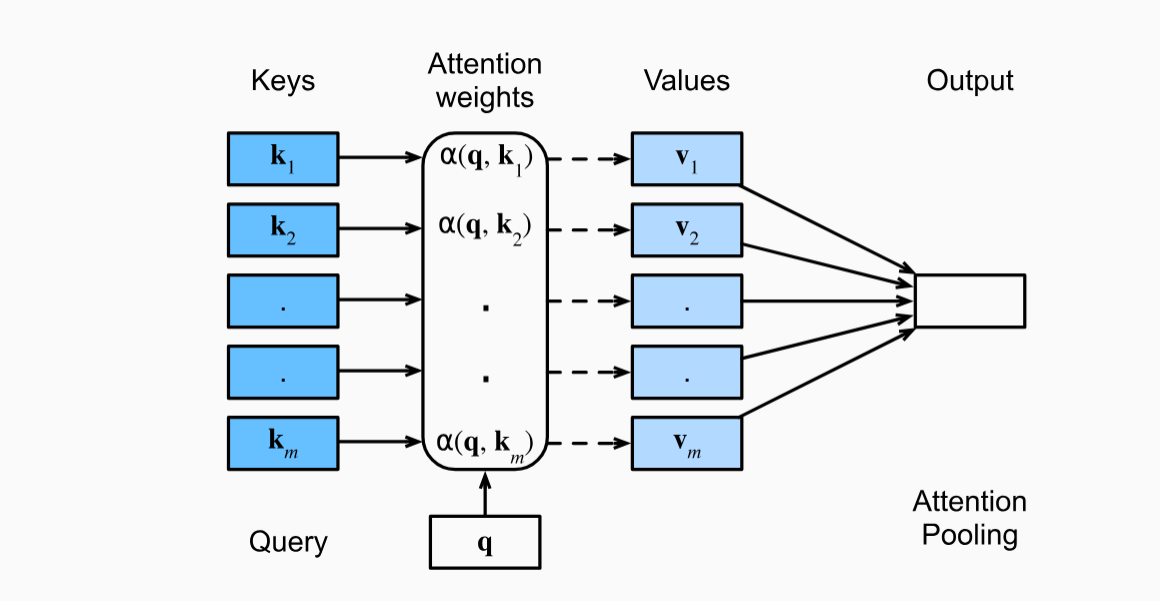



The figure summarizes the complete attention process.

For each source position:

1. The **query** $q$ is compared with the **key** $k_i$.
2. The resulting compatibility scores are normalized to produce the **attention weights** $\alpha(q,k_i)$.
3. Each attention weight determines how much of the corresponding **value** $v_i$ is used.
4. The weighted values are added together to produce the attention output.

$$
\operatorname{Attention}(q)
=
\sum_{i=1}^{m}
\alpha(q,k_i)v_i
$$

So, conceptually:

`Query + Keys → Scores → Attention Weights → Weighted Values → Attention Output`

**Remember:** the keys help determine the weights; the values provide the information that is combined.

### Attention: Key Takeaways

The attention mechanism allows the model to **select and combine relevant information** from a set of representations.

At a particular step:

**1. Query** $q$  
Represents the information being searched for.

**2. Keys** $k_1, k_2, \ldots, k_T$  
Are compared with the query to determine which positions are relevant.

**3. Attention weights** $\alpha(q,k_i)$  
Represent the relative importance of each position.

The weights satisfy:

$$
\sum_{i=1}^{T}\alpha(q,k_i)=1
$$

**4. Values** $v_1, v_2, \ldots, v_T$  
Contain the information that will actually be combined.

The attention output is:

$$
\operatorname{Attention}(q)
=
\sum_{i=1}^{T}\alpha(q,k_i)v_i
$$

Therefore:

`Query + Keys → Attention Weights → Weighted Values → Attention Output`

For our Seq2Seq translation model, this allows the decoder to retrieve different information from the source sequence depending on what it needs at a particular decoding step.

### Main Idea

Attention gives the decoder a **learnable way to select the source information that is most useful at each decoding step**, rather than relying on the same fixed representation for every prediction.

